# Phase 3 — Experiments
### Multi-Task Visual Counting and Localization in Dense Scenes

Each step changes one thing and is scored the same way, on the same 484 test images (the CARPK **TPZ** lot + PUCPR+).

| Step | Run | Model | Change |
|---|---|---|---|
| 1 | `full` (Phase 2, section 8) | YOLO11n | baseline: Ultralytics defaults, early stopping |
| 2 | `v2_full_schedule` (A) | YOLO11n | full 100-epoch schedule |
| 2 | `v2_flipud` (B) | YOLO11n | A + vertical flip |
| 3 | `cv_GF1`, `cv_GF2`, `cv_NTU` | YOLO11n | B, with one training lot held out as val |
| 4 | `yolo26n_baseline` | YOLO26n | baseline settings; scored with and without NMS |

**Scoring** (`src/3_phase/compare.py`)
- **Detection:** precision, recall, mAP50, mAP50-95 on test.
- **Counting:** count = number of boxes. MAE, RMSE and bias (predicted − true; above 0 = overcounting) over every test
  image, at Ultralytics' default `conf=0.25` and at a threshold chosen on val. Test is never used to choose anything.

Every training cell skips a run that already finished, so the notebook can be re-run top to bottom without retraining.

---
## 0. Setup

In [3]:
import shutil
import sys
from pathlib import Path

for p in (Path("src/3_phase").resolve(), Path("src/2_phase").resolve(), Path("src").resolve()):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import compare
import full_run
import lot_cv
from common import train_eval, training
from common.config import YOLO26_WEIGHTS
from common.model import ensure_weights

REF = Path("models/reference_full_best.pt")      # frozen copy of the baseline's best.pt
if not REF.exists():
    shutil.copy2("runs/train/full/weights/best.pt", REF)

FULL_SCHEDULE = dict(patience=0)                  # run A
RECIPE_B = dict(patience=0, flipud=0.5)          # run B
best = lambda name: Path("runs/train") / name / "weights" / "best.pt"
COLS = ["mAP50(B)", "mAP50-95(B)", "MAE @0.25", "bias @0.25", "tuned conf", "MAE @tuned", "bias @tuned"]
show = lambda result: result["summary"][COLS].astype(float).round(3)

---
## 1. Baseline — YOLO11n, no additions
Trained in Phase 2, section 8 (`runs/train/full`). Early stopping ended it at epoch 29 (best epoch 24).

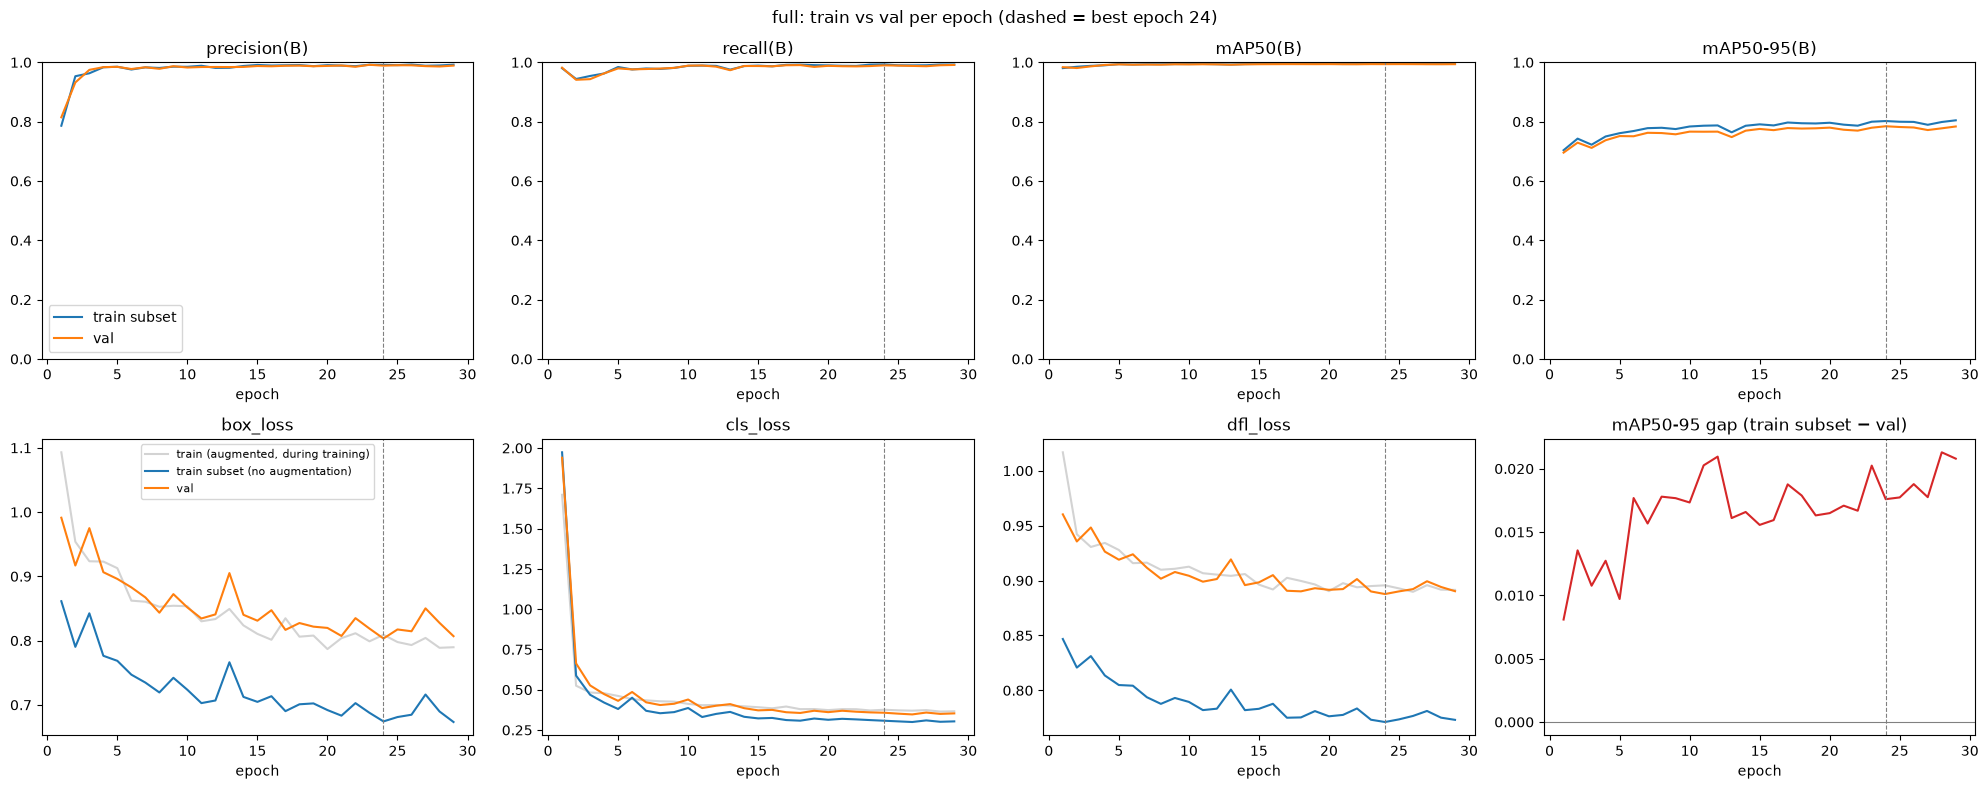

In [2]:
full_run.plot_curves(Path("runs/train/full"));

### 1.1 Accuracy

In [3]:
res1 = compare.compare({"baseline": REF})
show(res1)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 15946MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9864.5±1540.3 MB/s, size: 1301.2 KB)
val: Scanning /home/mariusz_godlewski/car_recognition/datasets/yolo/labels/test.cache... 484 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 484/484 225.6Mit/s 0.0s
val: /home/mariusz_godlewski/car_recognition/datasets/yolo/images/test/carpk__20161225_TPZ_00437.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 7.0it/s 4.4s<0.1s
                   all        484      51419      0.978      0.952      0.978      0.674
Speed: 0.8ms preprocess, 2.1ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /home/mariusz_godlewski/car_recognition/runs/compare/baseline_test
baseline: conf 0.500 (tuned on val of yol

,mAP50(B),mAP50-95(B),MAE @0.25,bias @0.25,tuned conf,MAE @tuned,bias @tuned
baseline,0.978,0.674,7.097,6.362,0.5,3.161,-1.649


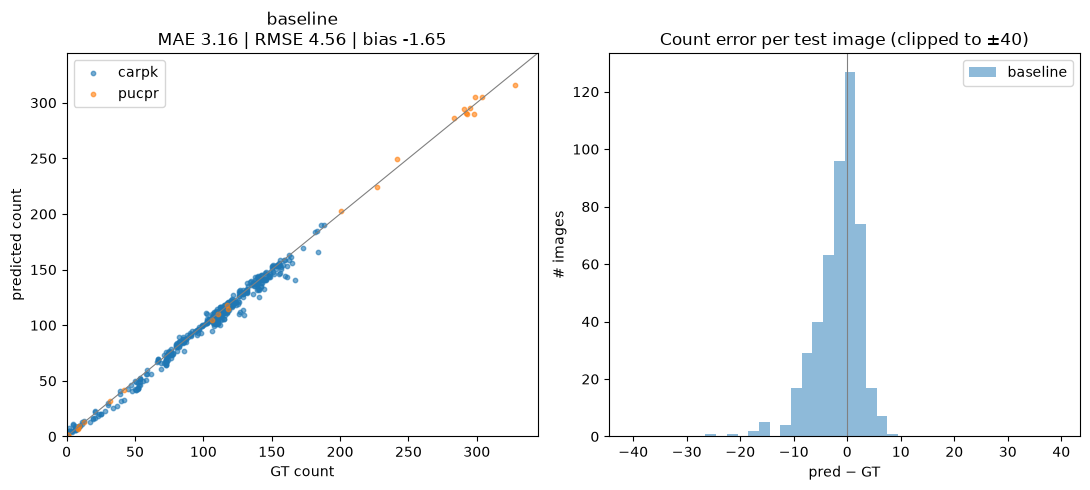

In [4]:
compare.plot_counts(res1);

**Result.** Test mAP50 0.978, mAP50-95 0.674. At `conf=0.25` the baseline overcounts (MAE 7.10 cars per image);
the threshold tuned on val (0.50) brings MAE down to 3.16. Val mAP50-95 was still rising when training stopped.

---
## 2. Longer training and augmentation
- **A — full schedule:** no early stopping, so training runs all 100 epochs, including the full learning-rate decay and the
  last 10 epochs without mosaic.
- **B — A + vertical flip** (`flipud=0.5`): aerial images have no natural "up".

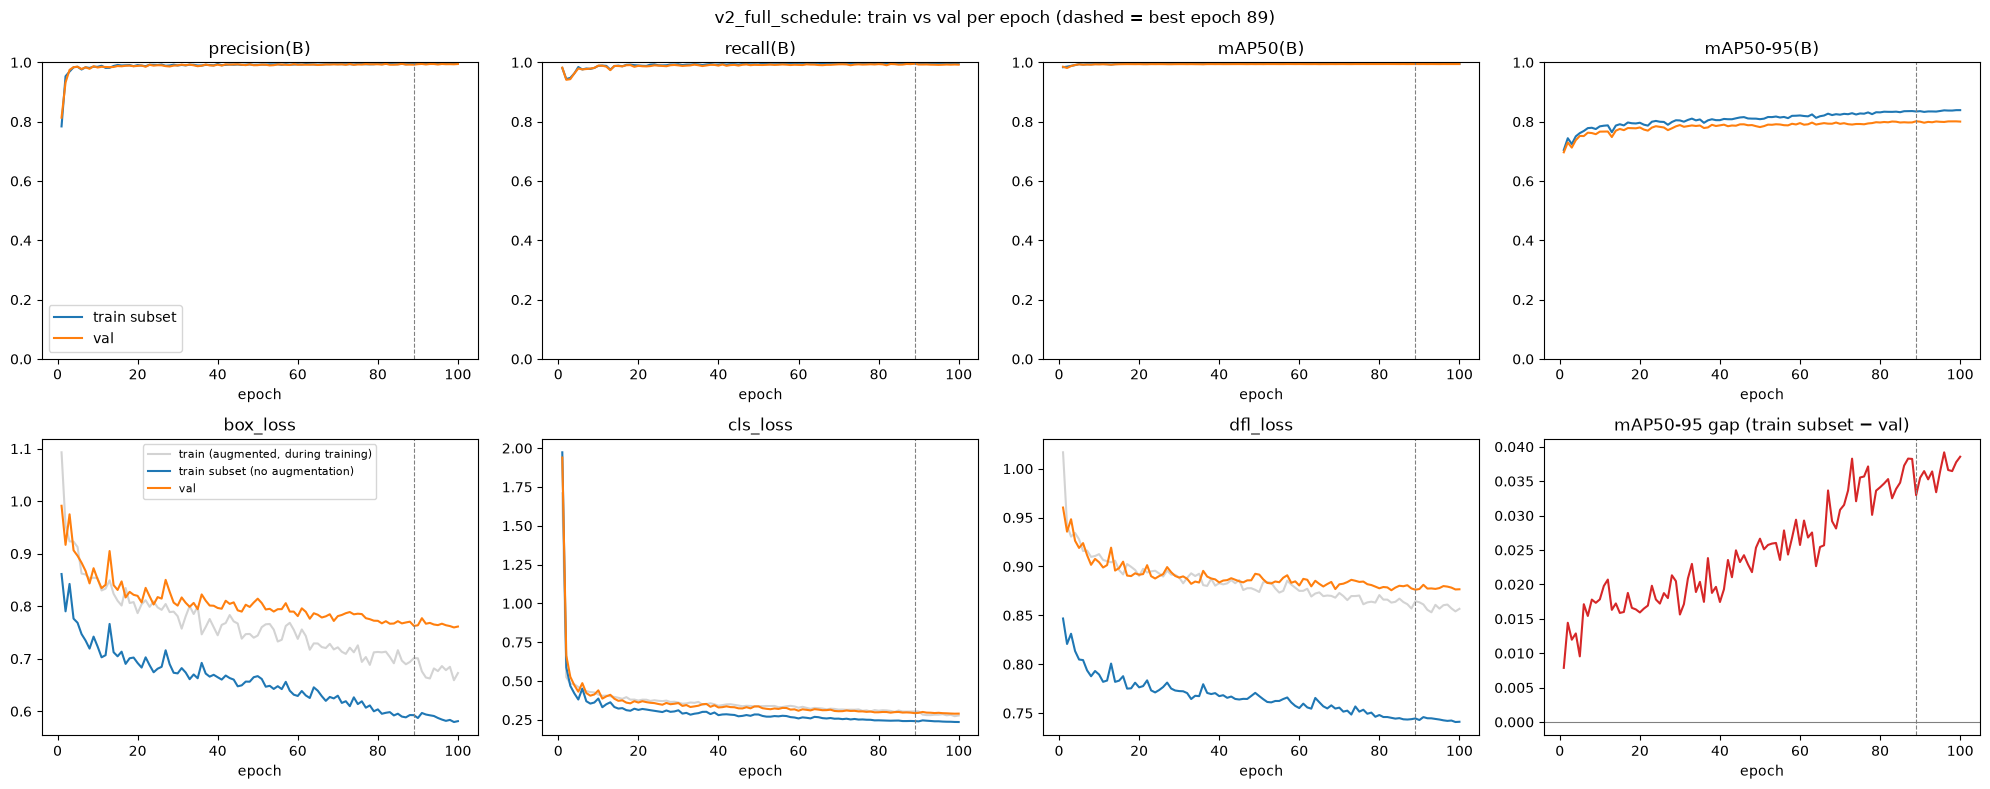

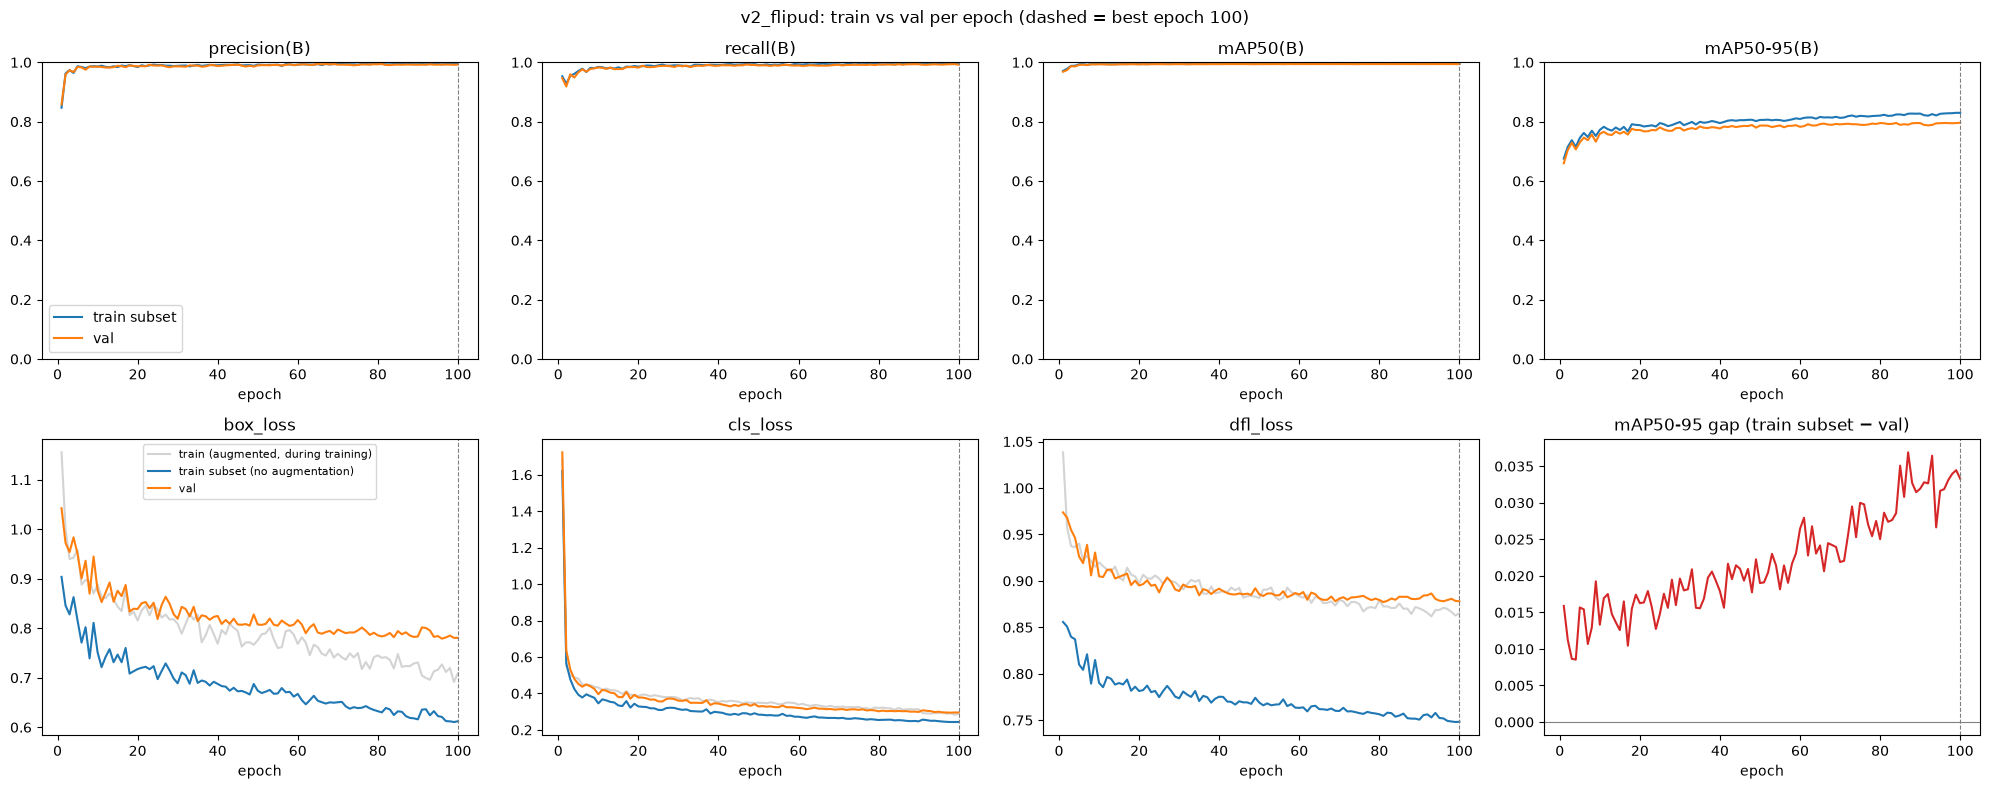

In [5]:
run_a = training.launch_once(training.train_args(name="v2_full_schedule", train_eval=True, **FULL_SCHEDULE))
run_b = training.launch_once(training.train_args(name="v2_flipud", train_eval=True, **RECIPE_B))
for run in (run_a, run_b):
    full_run.plot_curves(run);

### 2.1 Accuracy and comparison

In [6]:
res2 = compare.compare({"baseline": REF, "A": best("v2_full_schedule"), "B": best("v2_flipud")})
show(res2)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 15946MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11309.6±613.6 MB/s, size: 1412.8 KB)
val: Scanning /home/mariusz_godlewski/car_recognition/datasets/yolo/labels/test.cache... 484 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 484/484 406.0Mit/s 0.0s
val: /home/mariusz_godlewski/car_recognition/datasets/yolo/images/test/carpk__20161225_TPZ_00437.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 7.0it/s 4.4s<0.1s
                   all        484      51419      0.978      0.952      0.978      0.674
Speed: 0.8ms preprocess, 2.6ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /home/mariusz_godlewski/car_recognition/runs/compare/baseline_test
Ultralytics 8.4.185 🚀 Python-3.12.3 torch

,mAP50(B),mAP50-95(B),MAE @0.25,bias @0.25,tuned conf,MAE @tuned,bias @tuned
baseline,0.978,0.674,7.097,6.362,0.500,3.161,-1.649
A,0.980,0.704,3.428,1.382,0.525,3.665,-3.169
B,0.981,0.708,3.326,1.128,0.500,3.721,-2.994


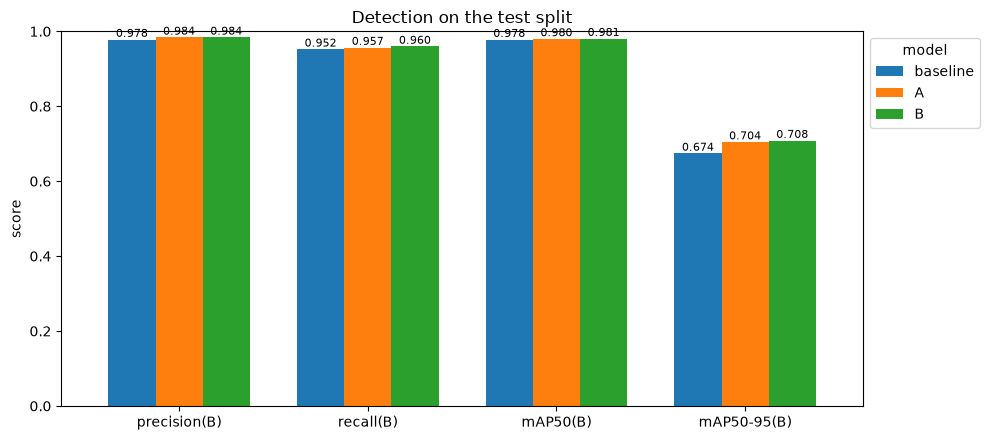

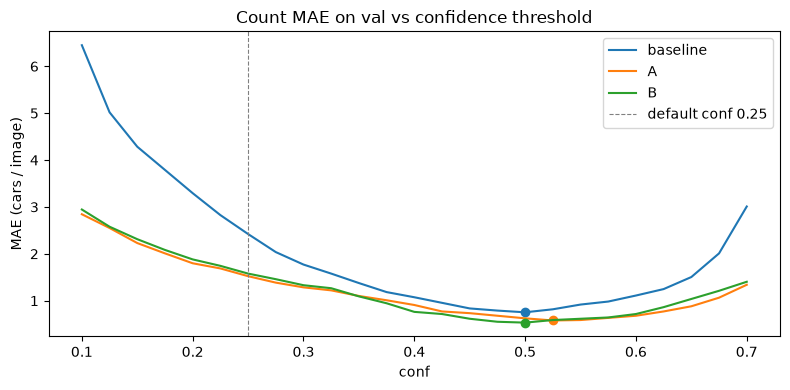

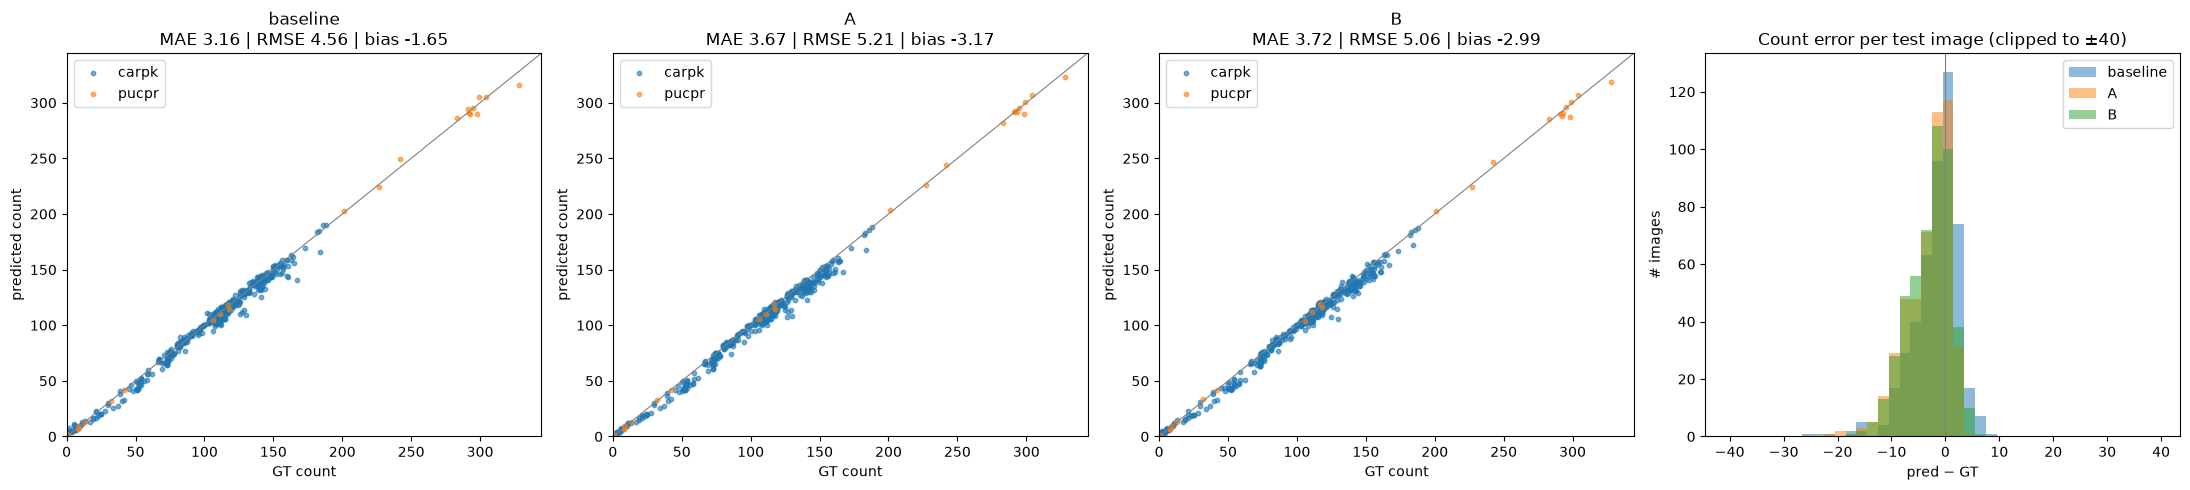

In [7]:
compare.plot_summary(res2); compare.plot_sweeps(res2); compare.plot_counts(res2);

**Result.** mAP50-95 rises from 0.674 to 0.704 (A) and 0.708 (B), and MAE at `conf=0.25` halves: 7.10 → 3.43 → 3.33.
The vertical flip adds little (+0.004 mAP50-95, within run-to-run noise). But the thresholds tuned on val (0.53 and 0.50)
make A and B *worse* on test (MAE 3.67 and 3.72, bias −3.2 and −3.0): they undercount the test lot.

---
## 3. A different split — hold out whole parking lots
The random val split is drawn from the training lots, while test is a lot the model never sees:

In [9]:
compare.lots_per_split()

split,train,val,test
lot,,,
carpk:GF1,366,32,0
carpk:GF2,312,36,0
carpk:NTU,214,29,0
carpk:TPZ,0,0,459
pucpr,88,12,25


TPZ appears only in test. So val measures performance on lots the model has seen, and the choices made on it
(threshold, best epoch) need not hold for TPZ. **Leave-one-lot-out cross-validation:** three folds, each with one whole
training lot (+10% of PUCPR+) as val and recipe B trained on the rest. The official test split is unchanged.

In [10]:
yamls = lot_cv.build_folds()
lot_cv.lots_table(yamls)

--- fold GF1 (val = carpk:GF1 + 10% of PUCPR+)
train:  681 images |  38088 boxes
val  :  408 images |  17127 boxes
test :  484 images |  51420 boxes
--- fold GF2 (val = carpk:GF2 + 10% of PUCPR+)
train:  731 images |  36565 boxes
val  :  358 images |  18650 boxes
test :  484 images |  51420 boxes
--- fold NTU (val = carpk:NTU + 10% of PUCPR+)
train:  836 images |  44194 boxes
val  :  253 images |  11021 boxes
test :  484 images |  51420 boxes


fold        GF1             GF2             NTU          
split     train  val test train  val test train  val test
lot                                                      
carpk:GF1     0  398    0   398    0    0   398    0    0
carpk:GF2   348    0    0     0  348    0   348    0    0
carpk:NTU   243    0    0   243    0    0     0  243    0
carpk:TPZ     0    0  459     0    0  459     0    0  459
pucpr        90   10   25    90   10   25    90   10   25

cv_GF1: already trained -> /home/mariusz_godlewski/car_recognition/runs/train/cv_GF1
cv_GF2: already trained -> /home/mariusz_godlewski/car_recognition/runs/train/cv_GF2
cv_NTU: already trained -> /home/mariusz_godlewski/car_recognition/runs/train/cv_NTU


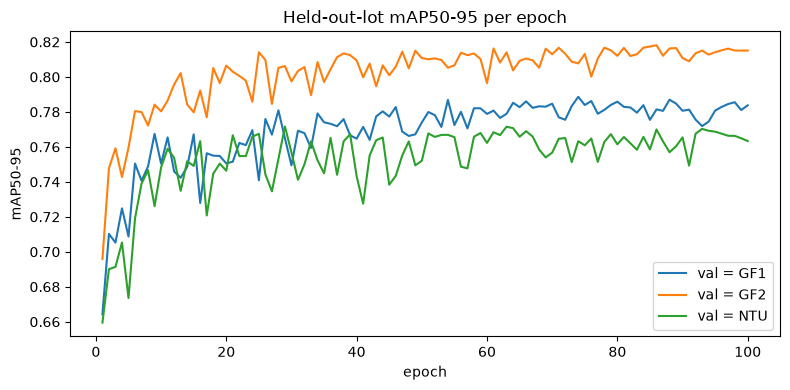

,epochs,best epoch,precision(B),recall(B),mAP50(B),mAP50-95(B)
GF1,100.0,74.0,0.988,0.981,0.994,0.789
GF2,100.0,86.0,0.990,0.991,0.994,0.818
NTU,100.0,29.0,0.974,0.955,0.979,0.772


In [11]:
cv_runs = lot_cv.run_folds(yamls, prefix="cv", **RECIPE_B)
lot_cv.plot_fold_curves(cv_runs)
lot_cv.fold_summary(cv_runs).round(3)

**Result.** On a held-out training lot mAP50-95 is 0.789 (GF1), 0.818 (GF2) and 0.772 (NTU) — about the same as on
the random val split (0.78). TPZ (about 0.70) is harder than "a lot the model has not seen": it has more than twice as many cars per
image (103 vs 43 in the CARPK training lots) and diagonal parking rows. NTU differs most from the other lots: its fold peaks at epoch 29, the others at 74 and 86.

### 3.1 Threshold from the held-out lots

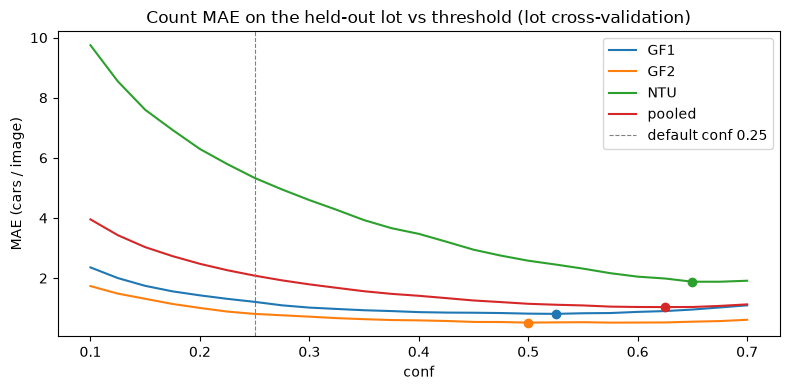

,images,best conf,MAE at best,MAE at 0.25
GF1,398.0,0.525,0.812,1.211
GF2,348.0,0.500,0.520,0.810
NTU,243.0,0.650,1.881,5.333
pooled,989.0,0.625,1.037,2.083


In [12]:
cv = lot_cv.cv_threshold(cv_runs, yamls)
lot_cv.plot_cv_threshold(cv)
cv["table"].round(3)

**Result.** The best threshold is 0.525 (GF1), 0.500 (GF2) and 0.650 (NTU); pooled 0.625. On every held-out training
lot the models *overcount* at 0.25, while on TPZ they *undercount* at 0.5. No single threshold carries over from the
training lots to TPZ.

### 3.2 Test accuracy at the cross-validated threshold

In [13]:
c = cv["conf"]
res3 = compare.compare({
    "baseline": REF,
    "baseline @cv": {"weights": REF, "conf": c},
    "A @cv": {"weights": best("v2_full_schedule"), "conf": c},
    "B @cv": {"weights": best("v2_flipud"), "conf": c},
    **{f"cv_{lot_cv.short(l)}": {"weights": d / "weights" / "best.pt", "conf": c} for l, d in cv_runs.items()},
})
show(res3)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 15946MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11307.4±577.5 MB/s, size: 1221.3 KB)
val: Scanning /home/mariusz_godlewski/car_recognition/datasets/yolo/labels/test.cache... 484 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 484/484 507.5Mit/s 0.0s
val: /home/mariusz_godlewski/car_recognition/datasets/yolo/images/test/carpk__20161225_TPZ_00437.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 7.0it/s 4.4s<0.1s
                   all        484      51419      0.978      0.952      0.978      0.674
Speed: 0.5ms preprocess, 2.7ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /home/mariusz_godlewski/car_recognition/runs/compare/baseline_test
Ultralytics 8.4.185 🚀 Python-3.12.3 torch

,mAP50(B),mAP50-95(B),MAE @0.25,bias @0.25,tuned conf,MAE @tuned,bias @tuned
baseline,0.978,0.674,7.097,6.362,0.500,3.161,-1.649
baseline @cv,0.978,0.674,7.097,6.362,0.625,5.341,-4.981
A @cv,0.980,0.704,3.428,1.382,0.625,5.072,-4.899
B @cv,0.981,0.708,3.326,1.128,0.625,5.256,-5.008
cv_GF1,0.981,0.727,4.068,2.994,0.625,4.023,-3.667
cv_GF2,0.979,0.706,3.752,1.715,0.625,5.808,-5.585
cv_NTU,0.972,0.658,11.897,11.541,0.625,4.413,-3.488


In [14]:
res3["by_source"].round(2)

images   MAE   RMSE  bias  rel_err_%
model        source                                      
baseline     carpk      459  3.21   4.60 -1.72       3.10
             pucpr       25  2.24   3.73 -0.40       1.43
baseline @cv carpk      459  5.13   6.97 -4.75       4.95
             pucpr       25  9.28  13.05 -9.28       5.92
A @cv        carpk      459  5.08   6.98 -4.90       4.91
             pucpr       25  4.96   7.55 -4.88       3.16
B @cv        carpk      459  5.17   7.14 -4.91       5.00
             pucpr       25  6.76   9.49 -6.76       4.31
cv_GF1       carpk      459  3.94   5.36 -3.57       3.81
             pucpr       25  5.48   7.94 -5.48       3.49
cv_GF2       carpk      459  5.62   7.50 -5.38       5.43
             pucpr       25  9.32  13.21 -9.32       5.94
cv_NTU       carpk      459  4.17   5.45 -3.19       4.03
             pucpr       25  8.92  12.39 -8.92       5.69

**Result.** _To fill in after the run: MAE and bias of A @cv and B @cv compared with section 2.1._

---
## 4. YOLO26n — a detector without NMS
On TPZ the cars stand in diagonal rows, so the axis-aligned boxes of neighbouring cars overlap heavily, and NMS may
delete real cars as duplicates. **YOLO26** trains a second, one-to-one head that needs no NMS, and adds losses aimed at
small objects. One YOLO26 checkpoint holds both heads; Ultralytics uses the one-to-many head + NMS unless `nms=False`
is passed, so the same model is scored both ways.

YOLO26n is trained with **the baseline's settings** (Ultralytics defaults, early stopping after 5 epochs), so it is
compared like for like with section 1.

### 4.1 Does NMS remove real cars in YOLO11n?
Model B at `conf=0.25` with three NMS IoU thresholds. A higher IoU suppresses less: if the count rises towards the
true count and MAE falls, NMS is removing real cars. This is a diagnosis on test; nothing is tuned on it.

In [8]:
compare.nms_check(best("v2_flipud")).round(2)

,mean count,mean GT,MAE,RMSE,bias,rel_err_%
NMS iou,,,,,,
0.5,105.83,106.24,2.74,3.81,-0.41,2.57
0.7,107.37,106.24,3.33,5.08,1.13,3.13
0.9,127.09,106.24,21.15,28.62,20.85,19.91


### 4.2 Train

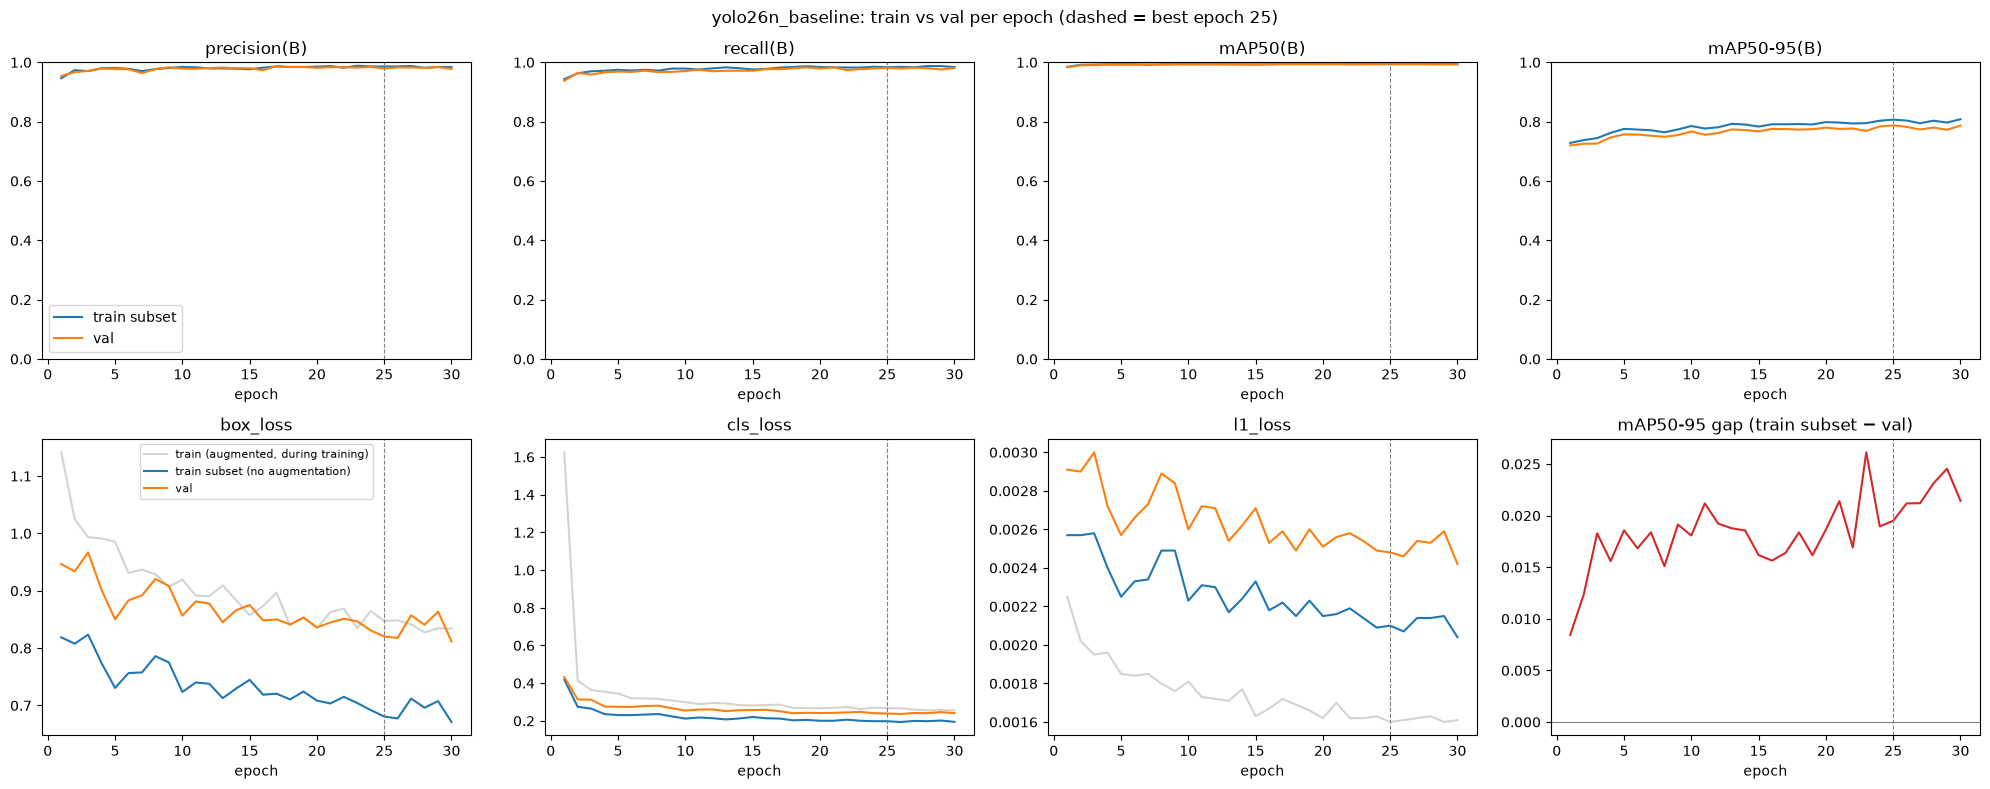

In [15]:
ensure_weights(YOLO26_WEIGHTS)    # official yolo26n.pt into models/
y26_run = training.launch_once(training.train_args(name="yolo26n_baseline", train_eval=True, nms=False),
                               weights=YOLO26_WEIGHTS)
full_run.plot_curves(y26_run);

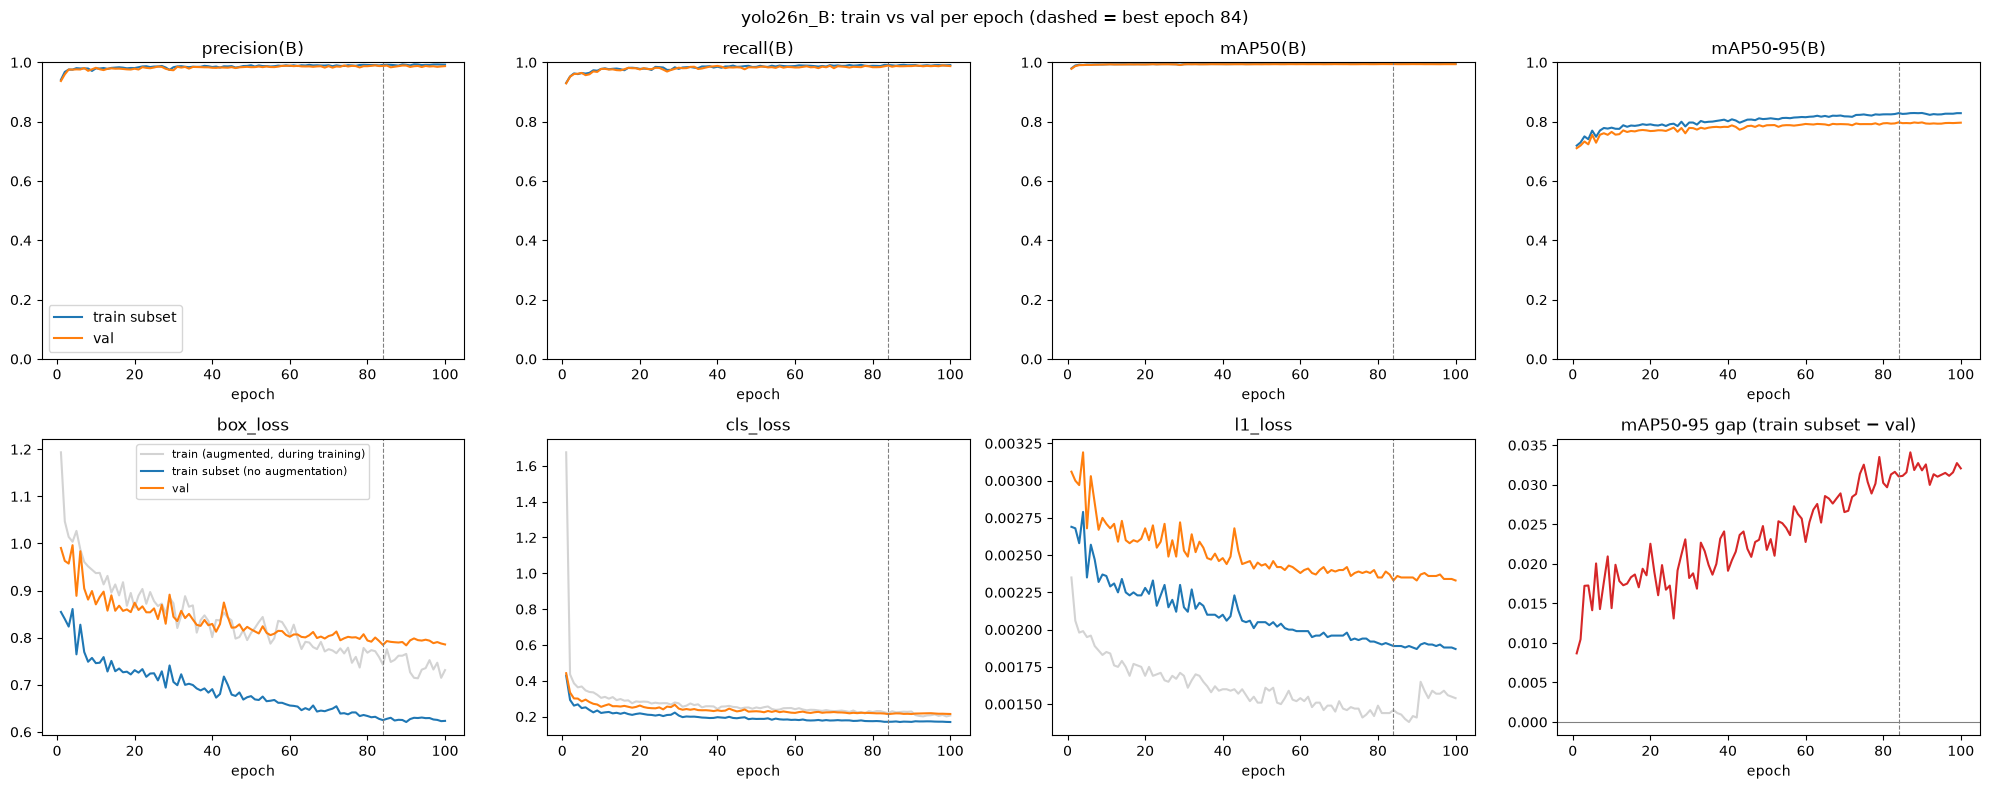

In [20]:
ensure_weights(YOLO26_WEIGHTS)    # official yolo26n.pt into models/
y26_full_run = training.launch_once(training.train_args(name="yolo26n_B", train_eval=True, nms=False, **RECIPE_B),
                               weights=YOLO26_WEIGHTS)
full_run.plot_curves(y26_full_run);

### 4.3 Accuracy and comparison with YOLO11n

In [21]:
y26 = y26_run / "weights" / "best.pt"
y26_b = y26_full_run / "weights" / "best.pt"
res4 = compare.compare({
    "YOLO11n baseline": REF,
    "YOLO26n + NMS": y26,
    "YOLO26n no NMS": {"weights": y26, "nms": False},
    "YOLO11n B": best("v2_flipud"),
    "YOLO26n B + NMS": y26_b
})
show(res4)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 15946MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11391.7±690.3 MB/s, size: 1268.8 KB)
val: Scanning /home/mariusz_godlewski/car_recognition/datasets/yolo/labels/test.cache... 484 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 484/484 406.0Mit/s 0.0s
val: /home/mariusz_godlewski/car_recognition/datasets/yolo/images/test/carpk__20161225_TPZ_00437.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 7.0it/s 4.4s<0.1s
                   all        484      51419      0.978      0.952      0.978      0.674
Speed: 0.9ms preprocess, 2.3ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /home/mariusz_godlewski/car_recognition/runs/compare/YOLO11n baseline_test
Ultralytics 8.4.185 🚀 Python-3.12

,mAP50(B),mAP50-95(B),MAE @0.25,bias @0.25,tuned conf,MAE @tuned,bias @tuned
YOLO11n baseline,0.978,0.674,7.097,6.362,0.500,3.161,-1.649
YOLO26n + NMS,0.982,0.726,3.810,1.554,0.525,3.860,-3.430
YOLO26n no NMS,0.977,0.708,5.217,1.527,0.475,4.386,-2.928
YOLO11n B,0.981,0.708,3.326,1.128,0.500,3.721,-2.994
YOLO26n B + NMS,0.982,0.732,3.159,-0.341,0.450,3.335,-2.839


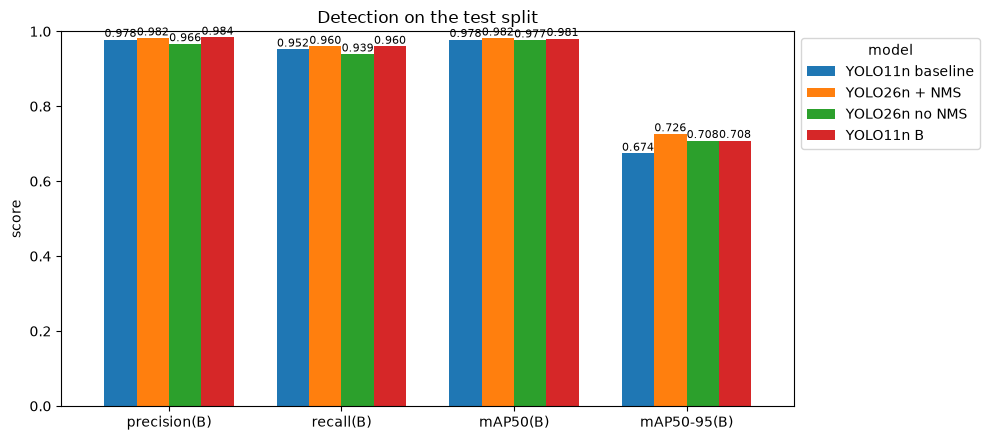

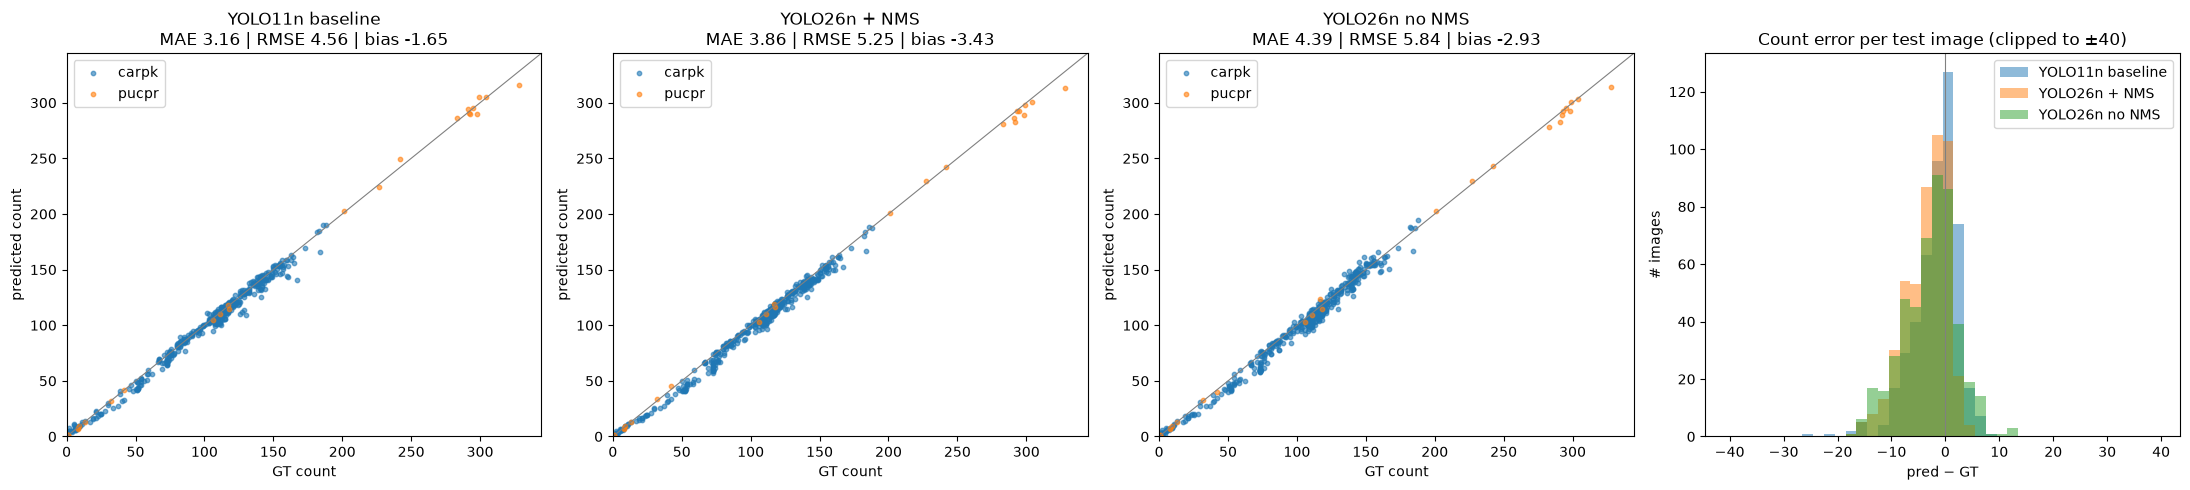

In [17]:
compare.plot_summary(res4); compare.plot_counts(res4, ["YOLO11n baseline", "YOLO26n + NMS", "YOLO26n no NMS"]);

In [19]:
compare.head_to_head(res4, "YOLO26n no NMS", "YOLO26n + NMS").head(10)

closer
YOLO26n + NMS     225
YOLO26n no NMS    144
tie               115


,source,gt,pred YOLO26n no NMS,pred YOLO26n + NMS,|err| YOLO26n no NMS,|err| YOLO26n + NMS,closer
image,,,,,,,
carpk__20161225_TPZ_00330,carpk,184,167,167,17,17,tie
carpk__20161225_TPZ_00415,carpk,167,151,152,16,15,YOLO26n + NMS
carpk__20161225_TPZ_00183,carpk,112,96,97,16,15,YOLO26n + NMS
carpk__20161225_TPZ_00244,carpk,130,115,116,15,14,YOLO26n + NMS
carpk__20161225_TPZ_00355,carpk,141,126,125,15,16,YOLO26n no NMS
carpk__20161225_TPZ_00112,carpk,73,58,62,15,11,YOLO26n + NMS
carpk__20161225_TPZ_00111,carpk,73,58,60,15,13,YOLO26n + NMS
carpk__20161225_TPZ_00116,carpk,73,59,60,14,13,YOLO26n + NMS
carpk__20161225_TPZ_00110,carpk,74,60,62,14,12,YOLO26n + NMS


**Result.** _To fill in after the run: YOLO26n no NMS vs + NMS (does removing NMS help?) and vs the YOLO11n baseline._

---
## 5. Conclusions
- Training longer mattered most: mAP50-95 0.674 → 0.704 and count MAE at `conf=0.25` 7.10 → 3.43.
- Vertical flip added little (+0.004 mAP50-95), so further augmentation is unlikely to close the gap.
- The test lot behaves differently from every training lot: a confidence threshold chosen on the training lots makes the
  models undercount TPZ.
- _YOLO26n: to fill in._

**Next step.** If YOLO26n does not close the gap on TPZ, try a larger model (`yolo11s`, 9.4M parameters, or `yolo26s`).

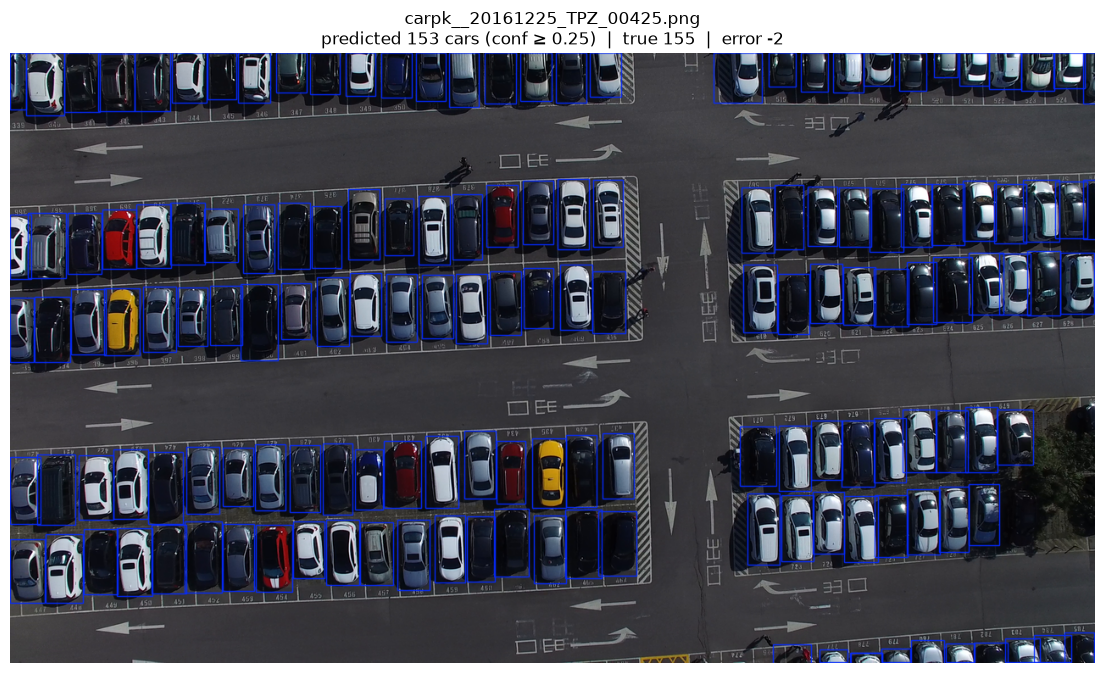

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'car'}
obb: None
orig_img: array([[[ 40,  33,  35],
        [ 43,  17,  19],
        [ 52,  13,  18],
        ...,
        [ 72,  62,  48],
        [ 82,  61,  48],
        [ 55,  31,  14]],

       [[ 42,  34,  36],
        [ 46,  20,  22],
        [ 80,  40,  46],
        ...,
        [ 92,  81,  66],
        [101,  79,  67],
        [ 61,  37,  22]],

       [[ 30,  15,  26],
        [ 58,  32,  36],
        [142, 112, 110],
        ...,
        [121, 109,  95],
        [116,  93,  84],
        [ 54,  30,  18]],

       ...,

       [[ 62,  62,  62],
        [ 67,  67,  67],
        [ 67,  67,  67],
        ...,
        [ 59,  41,  27],
        [ 65,  47,  33],
        [ 66,  48,  34]],

       [[ 67,  67,  67],
        [ 67,  67,  67],
        [ 65,  65,  65],
        ...,
        [ 53,  38,  24],
        [ 58,  42,  28],
    

In [11]:
BEST = "runs/train/yolo26n_B/weights/best.pt"       # your best model; adjust the run name if yours differs

full_run.show_prediction(BEST)                                # random test image
# full_run.show_prediction(BEST, seed=3)                        # same random image every time
# full_run.show_prediction(BEST, image="datasets/yolo/images/test/carpk__20161225_TPZ_00249.png")
# full_run.show_prediction(BEST, nms=False)                     # YOLO26's NMS-free head